# CsI–SiPM：固定雪崩历史的重复噪声与事件方差对照

2026-11-02。承接已提交并推送的 **82d42f8**（`Diagnose CsI PID fluctuation differences with Gaussian closure`）及[Gaussian闭合笔记](codex_0001_csi_gaussian_closure.ipynb)。原F202方差差异主要落在二阶闭合之外；本轮检验主带选择与读出随机性，并测试只去掉信号噪声的事件方差乘子是否能改善联合结果。

原有256000个Geant4母事件中，复用3661个已选母事件（Co 2175、Am 1486；原支持Q箱内为2175/1406）。新增198819条科学分析读出记录，来自788个物理输出文件，**新增独立Geant4母事件和实验事件均为0**。读出重复不增加独立输运统计量。API核验另有240条测试记录，不计入科学分析条数。

仍使用原CH0、53.2 V的run3与run12。Am源含α及γ/电子贡献；来源标签和QDC主带不能当作实验真值。旧数据及本MC池都已参与探索，本轮不是盲验证。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/noise_replay_20261102'
def read(path):return json.loads(Path(path).read_text())
def fmt(x):return '不可估计' if x is None else f'{x:.4g}'
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head,rows):return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'replay_protocol.json');selection=read(OUT/'selection_analysis.json')
points=read(OUT/'point_analysis.json');repeated=read(OUT/'repeat_analysis.json');decision=read(OUT/'decision.json')
display(Markdown('**本轮结论：**'+decision['conclusion_zh']))
for finding in decision['findings_zh']:display(Markdown(finding))
print('固定母事件:',p['fixed_selected_mothers'],'科学读出记录:',p['physical_replay_entries'])

固定母事件: 3661 科学读出记录: 198819


**本轮结论：**零CV对照未通过联合保护条件。保留当前默认参数；本轮明确检验了主带选择与随机读出贡献，并记录了降CV的收益和代价。

主带审计：所有36个固定MC条件/响应都通过既定0.4条件，统一主带后各宽度指标完全不变；这排除了本次主带删除差别作为当前MC偏宽的解释。

**Co60 晚段块128：**零号配对对照的F202 SD比从1.232 [1.168, 1.326]变为0.997 [0.947, 1.069]；F50 SD比从0.976 [0.889, 1.051]变为0.636 [0.578, 0.685]。两种尺度同时报告，不只选择改善的一项。

**Co60 重复噪声：**当前响应F202的同一母事件内方差比例为0.933 [0.925, 0.941]，不同母事件间的修正比例为0.067 [0.059, 0.075]。这是固定已有样本、有限重复校正后的条件分解。

**Am241 晚段块128：**零号配对对照的F202 SD比从1.201 [1.122, 1.312]变为1.176 [1.098, 1.281]；F50 SD比从0.941 [0.884, 1.027]变为0.892 [0.833, 0.969]。两种尺度同时报告，不只选择改善的一项。

**Am241 重复噪声：**当前响应F202的同一母事件内方差比例为0.986 [0.980, 0.993]，不同母事件间的修正比例为0.014 [0.007, 0.020]。这是固定已有样本、有限重复校正后的条件分解。

## 1. 主带选择是否造成不公平比较？

原比较保留实测主带（Co QDC≥0.4，Am QDC<0.4），MC没有这一步删除。本轮在全部前/中/晚段、块64/128及三个已有响应中，比较：完整已选实测队列、继承主带、双方按当前响应的同一0.4条件筛选、MC按冻结响应固定主带。每种情况仍按原Q半箱目标质量归一，缺失支持格就报告不可估计，不能偷偷删箱。

“完整已选”只是主带切分之前的队列，仍经过原质量和共同电荷范围选择。该对照不等于未触发、未筛选的真实源总体。


|run|主带条件|F202 SD比|条件95%范围|相对原比较变化|
|---|---|---|---|---|
|3|all_selected|1.234|[1.17, 1.318] (512/512)|0.001732|
|3|inherited|1.232|[1.168, 1.326] (512/512)|0|
|3|matched_band|1.232|[1.168, 1.326] (512/512)|0|
|3|fixed_MC_band|1.232|[1.168, 1.326] (512/512)|0|
|12|all_selected|1.201|[1.122, 1.312] (512/512)|0|
|12|inherited|1.201|[1.122, 1.312] (512/512)|0|
|12|matched_band|1.201|[1.122, 1.312] (512/512)|0|
|12|fixed_MC_band|1.201|[1.122, 1.312] (512/512)|0|

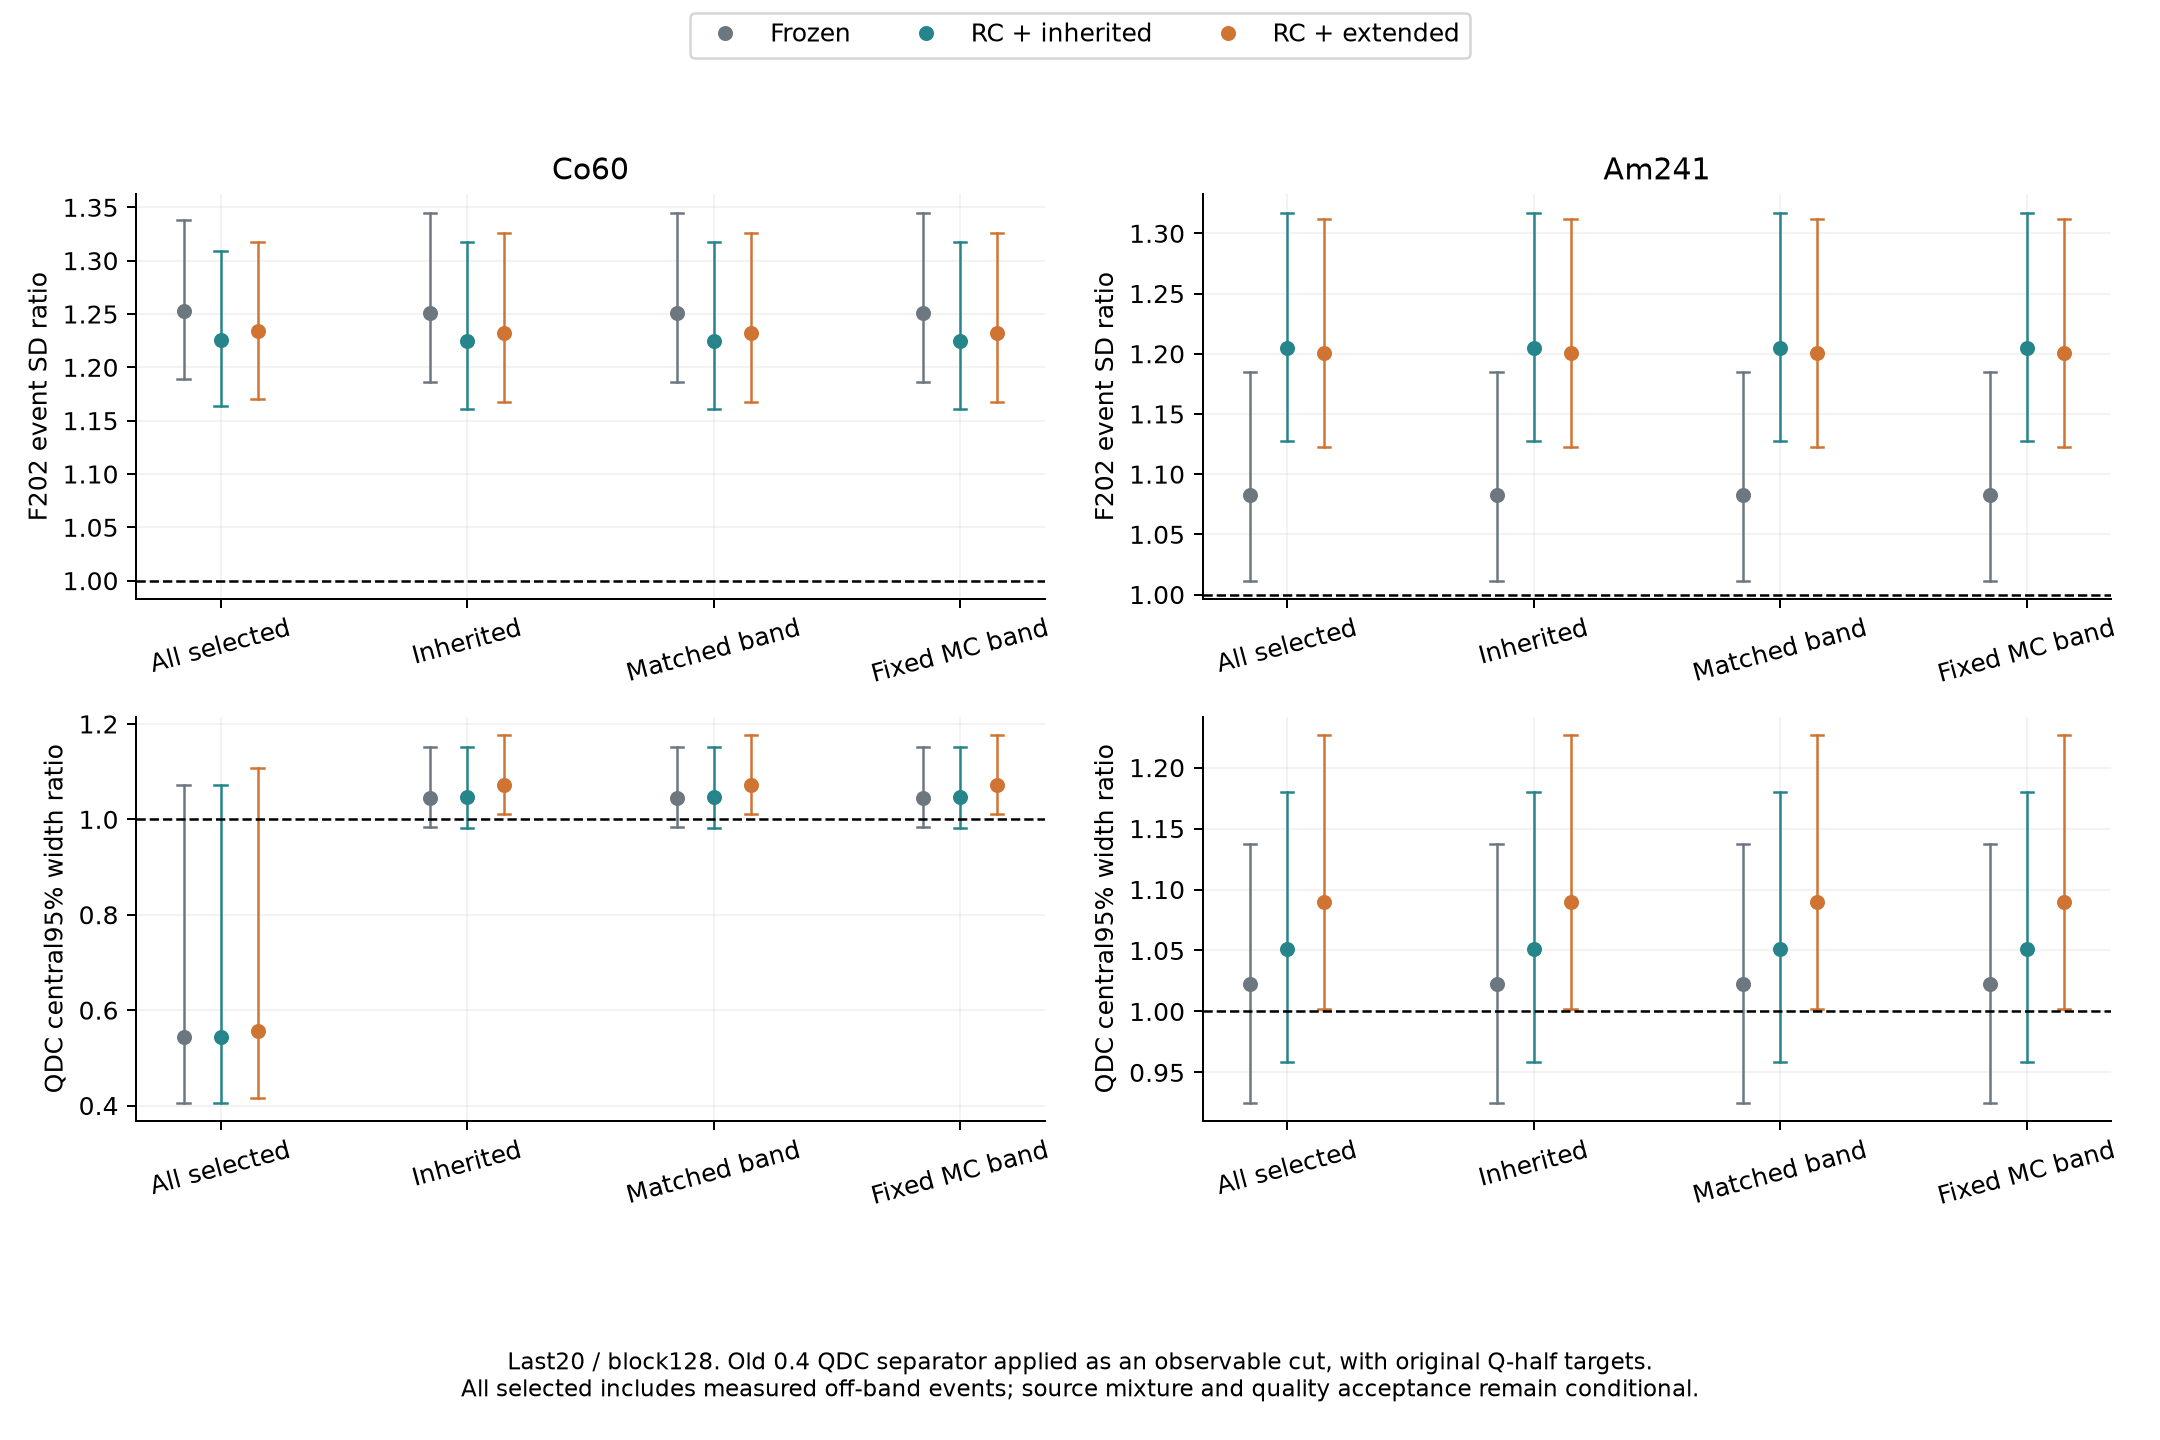

In [2]:
rows=[]
for run in [3,12]:
    g=selection['groups'][f'run{run}_last20']['128']
    for case in ['all_selected','inherited','matched_band','fixed_MC_band']:
        r=g['comparisons']['spectrum_CV_fit'][case]
        rows.append([run,case,fmt(r['point']['F202_SD_ratio']),ci(r['CI95']['F202_SD_ratio']),fmt(r['change_from_inherited']['F202_SD_ratio'])])
display(Markdown(table(['run','主带条件','F202 SD比','条件95%范围','相对原比较变化'],rows)))
display(Image(filename=str(OUT/'figures/noise_selection_audit.png')))

## 2. 原生C++重放：同一信号，只更换下游噪声

新增`include/ReadoutReplica.hh`、`src/ReadoutReplica.cc`，由原`replay_readout`入口调用；保留Geant4的include/src结构和完整输运入口。复用原ROOT中的雪崩时间、电荷和固定读出响应，不重新抽取光子、PDE、串扰或后脉冲。后者已在固定雪崩历史内，因此不能用本轮“母事件内噪声”估计它们的独立物理贡献。

`noise_replica=0`保留原随机种子及ADC；正编号在专用种子域重放，可复现同一编号。`noise_scope`为`all_readout`、`signal_only`或`electronics_only`。分别改变两条流、仅信号相关残差流、仅电子学流；单流对照把另一条流固定为零号实现，因此三者不能直接按方差相加。

主条件为晚段、块128、扩展残差谱：全部噪声16次、信号流8次、电子学流8次、零CV全部噪声16次。另在全部12个条件作零号配对对照。所有R与对照在结果前固定；没有根据结果追加重复或剔除事件。


In [3]:
tests=read(OUT/'replay_tests.json')
display(tests['native_tests'])
print('C++测试:',tests['ctest_passed'],'合成有限重复检验:',tests['algebra']['trials'])
for source,r in repeated.items():
    print(source,{k:{'R':v['repeat_count'],'负的母事件间对角项':v['negative_between_diagonal'],
                    '最大主带外事件数':max(x['outside_band'] for x in v['band_migrations'])} for k,v in r['cases'].items()})

C++测试: 6 合成有限重复检验: 2000
Co60 {'current_all': {'R': 16, '负的母事件间对角项': 0, '最大主带外事件数': 0}, 'current_signal': {'R': 8, '负的母事件间对角项': 0, '最大主带外事件数': 0}, 'current_electronics': {'R': 8, '负的母事件间对角项': 0, '最大主带外事件数': 0}, 'zero_cv_all': {'R': 16, '负的母事件间对角项': 0, '最大主带外事件数': 0}}
Am241 {'current_all': {'R': 16, '负的母事件间对角项': 0, '最大主带外事件数': 1}, 'current_signal': {'R': 8, '负的母事件间对角项': 0, '最大主带外事件数': 0}, 'current_electronics': {'R': 8, '负的母事件间对角项': 0, '最大主带外事件数': 0}, 'zero_cv_all': {'R': 16, '负的母事件间对角项': 0, '最大主带外事件数': 1}}


[{'source': 'Co60',
  'mothers': 6,
  'cases': 10,
  'cached_plain_bitwise': True,
  'zero_identity': True,
  'reproducibility': True,
  'unchanged_signal': True},
 {'source': 'Am241',
  'mothers': 6,
  'cases': 10,
  'cached_plain_bitwise': True,
  'zero_identity': True,
  'reproducibility': True,
  'unchanged_signal': True}]

## 3. 有限重复下的母事件内/间方差

在每个原Q箱内，令第i个母事件的R次9维特征为$X_{ir}$，权重$w_i$沿用原Q半箱目标且和为1。$\bar X_i$为重复均值，$S_i$为重复的`ddof=1`协方差：

\[
B_{raw}=\sum_i w_i(\bar X_i-\bar X)(\bar X_i-\bar X)^T,\quad
C_R=\sum_i\frac{w_i(1-w_i)}{R}S_i,\quad B=B_{raw}-C_R.
\]

本项目原统计使用归一权重的经验协方差，因此“一母事件一次读出”的预期方差为

\[
V_{one}=B+W_{one},\qquad W_{one}=\sum_i w_i(1-w_i)S_i.
\]

先逐原Q箱计算，再按原支持箱等权平均。有限R校正后的B可能为负，保留原值；不能把它截零或解释为纯闪烁方差。母事件间项含条件噪声均值、定位和随机分母效应。此公式估计的是固定所选母事件、重复读出条件下的量，不是全源总体的物理方差分解。

512次区间保持原实验索引块和四批完整母事件抽样。一个母事件的所有重复一起重抽；同一ID的重复副本先合并权重，再作有限R校正。区间固定模型、Q参考、响应折，不包括参数拟合或系统误差，也不把198819条记录当作独立样本。每条流的有限重复估计仍有Monte Carlo误差，预设前8/后8敏感性检查另报。


|源|重复流|指标|点值|条件95%范围|
|---|---|---|---|---|
|Co60|current_all|F202_predicted_SD_ratio|1.25|[1.206, 1.337] (512/512)|
|Co60|current_all|F202_within_fraction|0.9332|[0.925, 0.941] (512/512)|
|Co60|current_all|F202_between_fraction|0.06679|[0.05896, 0.07505] (512/512)|
|Co60|current_signal|F202_predicted_SD_ratio|1.257|[1.213, 1.346] (512/512)|
|Co60|current_signal|F202_within_fraction|0.8982|[0.8861, 0.9112] (512/512)|
|Co60|current_signal|F202_between_fraction|0.1018|[0.08877, 0.1139] (512/512)|
|Co60|current_electronics|F202_predicted_SD_ratio|1.226|[1.166, 1.318] (512/512)|
|Co60|current_electronics|F202_within_fraction|0.06322|[0.05909, 0.068] (512/512)|
|Co60|current_electronics|F202_between_fraction|0.9368|[0.932, 0.9409] (512/512)|
|Co60|zero_cv_all|F202_predicted_SD_ratio|1.026|[0.99, 1.095] (512/512)|
|Co60|zero_cv_all|F202_within_fraction|0.9012|[0.8916, 0.9113] (512/512)|
|Co60|zero_cv_all|F202_between_fraction|0.09878|[0.08868, 0.1084] (512/512)|
|Am241|current_all|F202_predicted_SD_ratio|1.21|[1.148, 1.308] (512/512)|
|Am241|current_all|F202_within_fraction|0.9861|[0.9802, 0.9933] (512/512)|
|Am241|current_all|F202_between_fraction|0.01388|[0.006695, 0.01983] (512/512)|
|Am241|current_signal|F202_predicted_SD_ratio|1.223|[1.154, 1.325] (512/512)|
|Am241|current_signal|F202_within_fraction|0.8657|[0.8459, 0.8855] (512/512)|
|Am241|current_signal|F202_between_fraction|0.1343|[0.1145, 0.1541] (512/512)|
|Am241|current_electronics|F202_predicted_SD_ratio|1.181|[1.107, 1.283] (512/512)|
|Am241|current_electronics|F202_within_fraction|0.2674|[0.2475, 0.287] (512/512)|
|Am241|current_electronics|F202_between_fraction|0.7326|[0.713, 0.7525] (512/512)|
|Am241|zero_cv_all|F202_predicted_SD_ratio|1.178|[1.12, 1.272] (512/512)|
|Am241|zero_cv_all|F202_within_fraction|0.9862|[0.98, 0.9932] (512/512)|
|Am241|zero_cv_all|F202_between_fraction|0.01379|[0.006832, 0.01995] (512/512)|

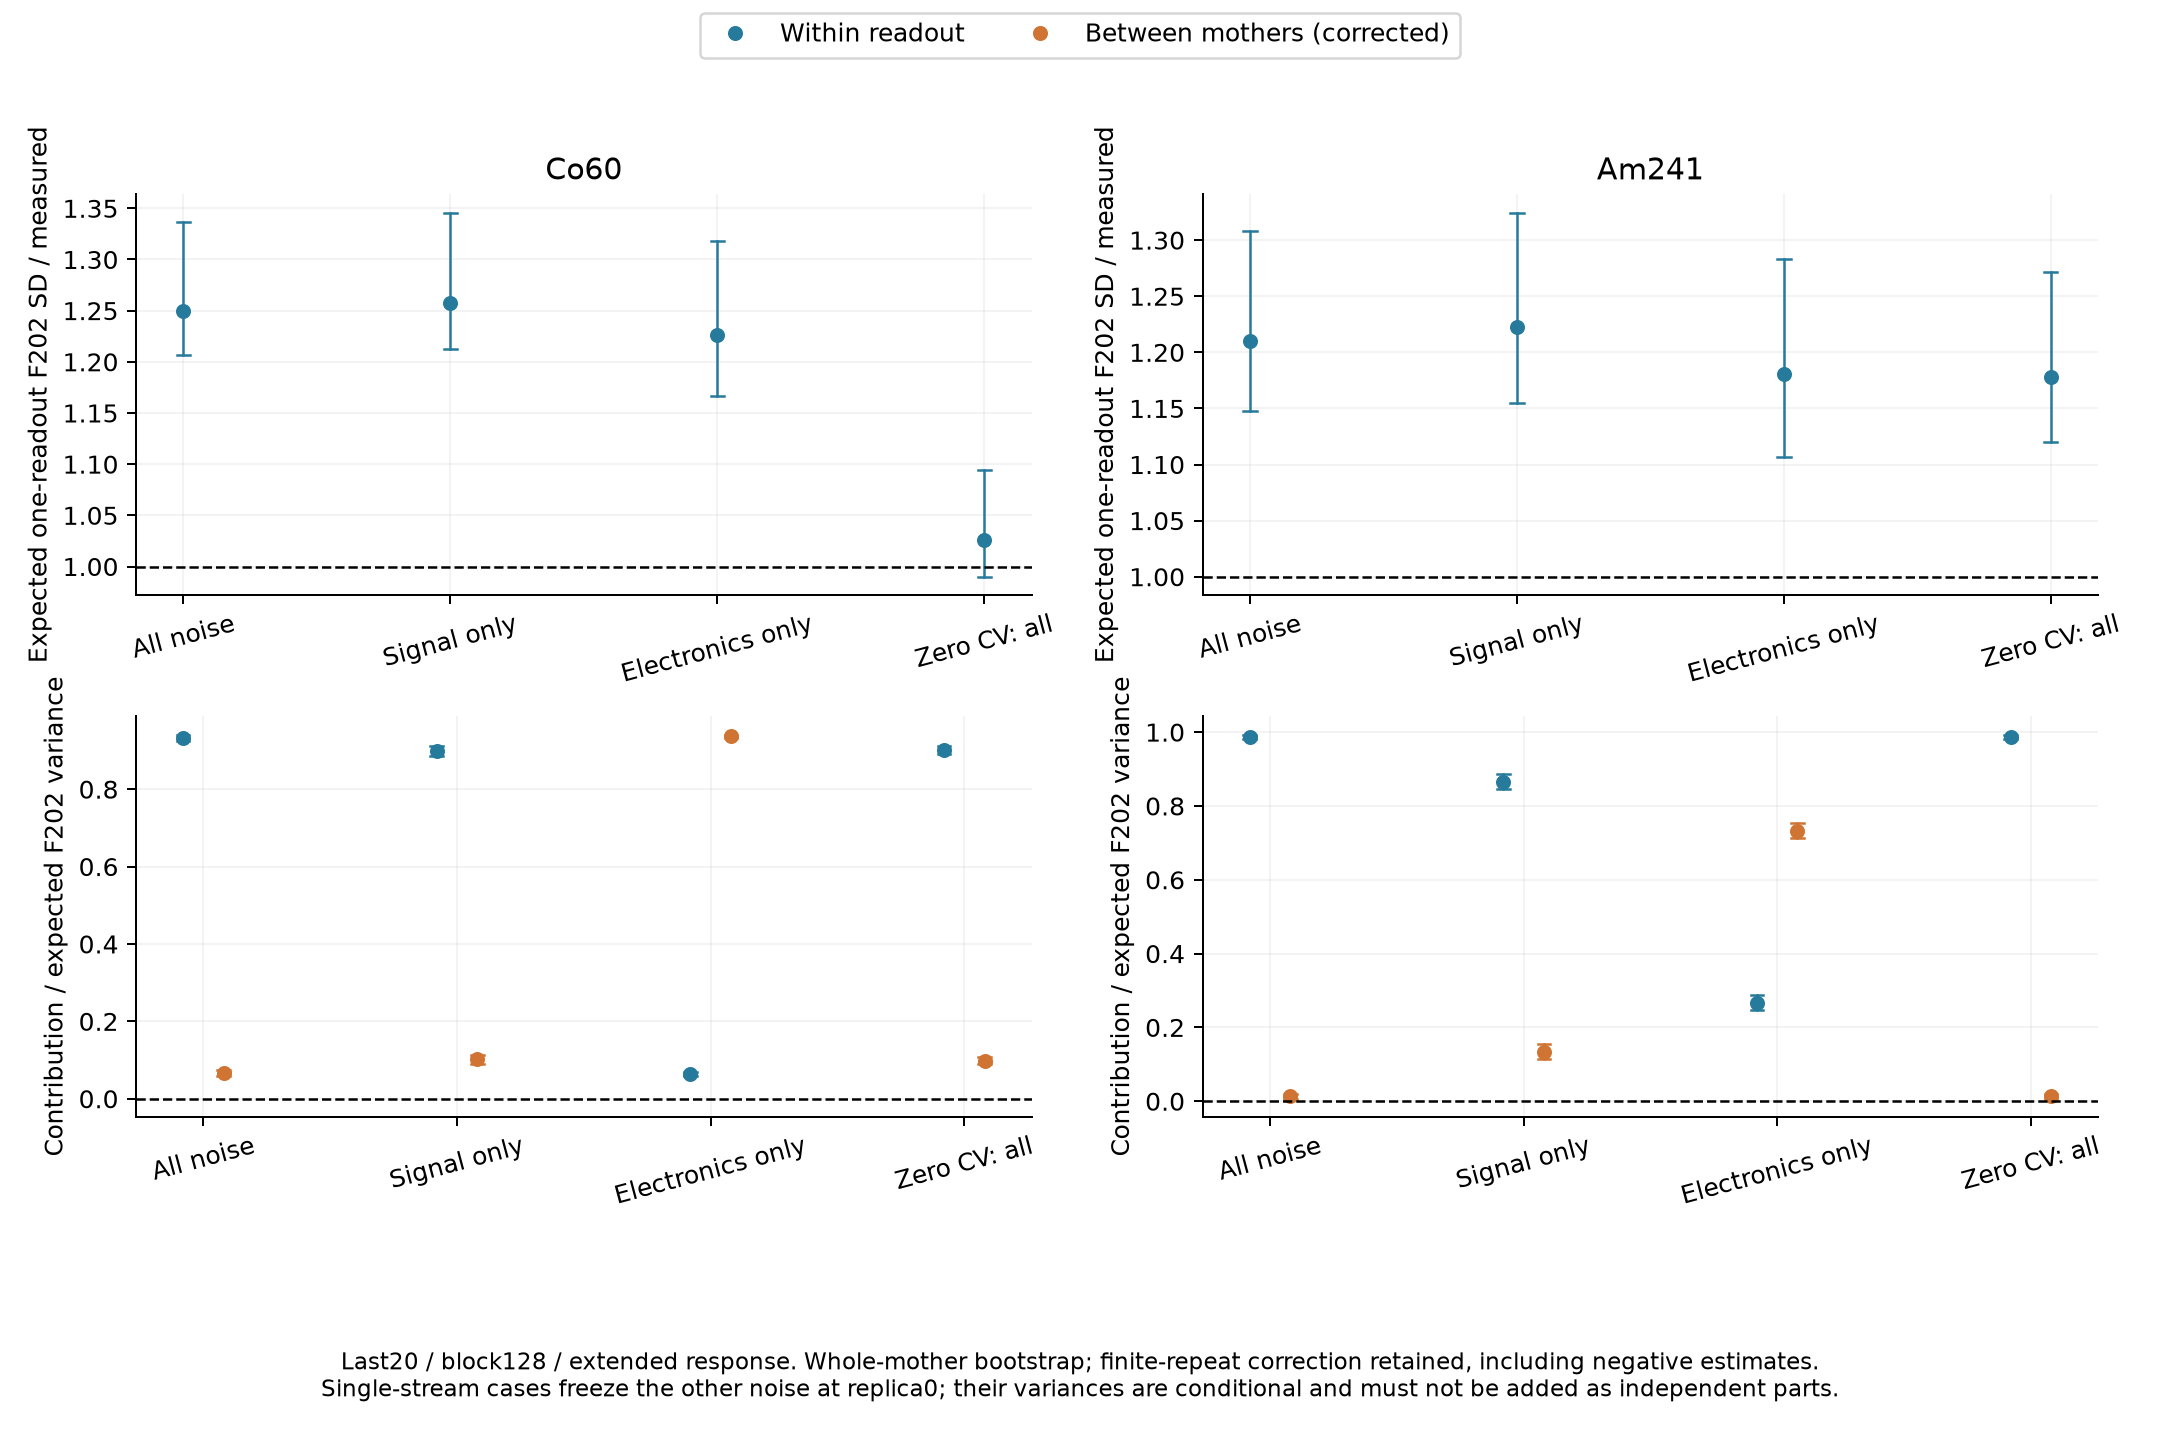

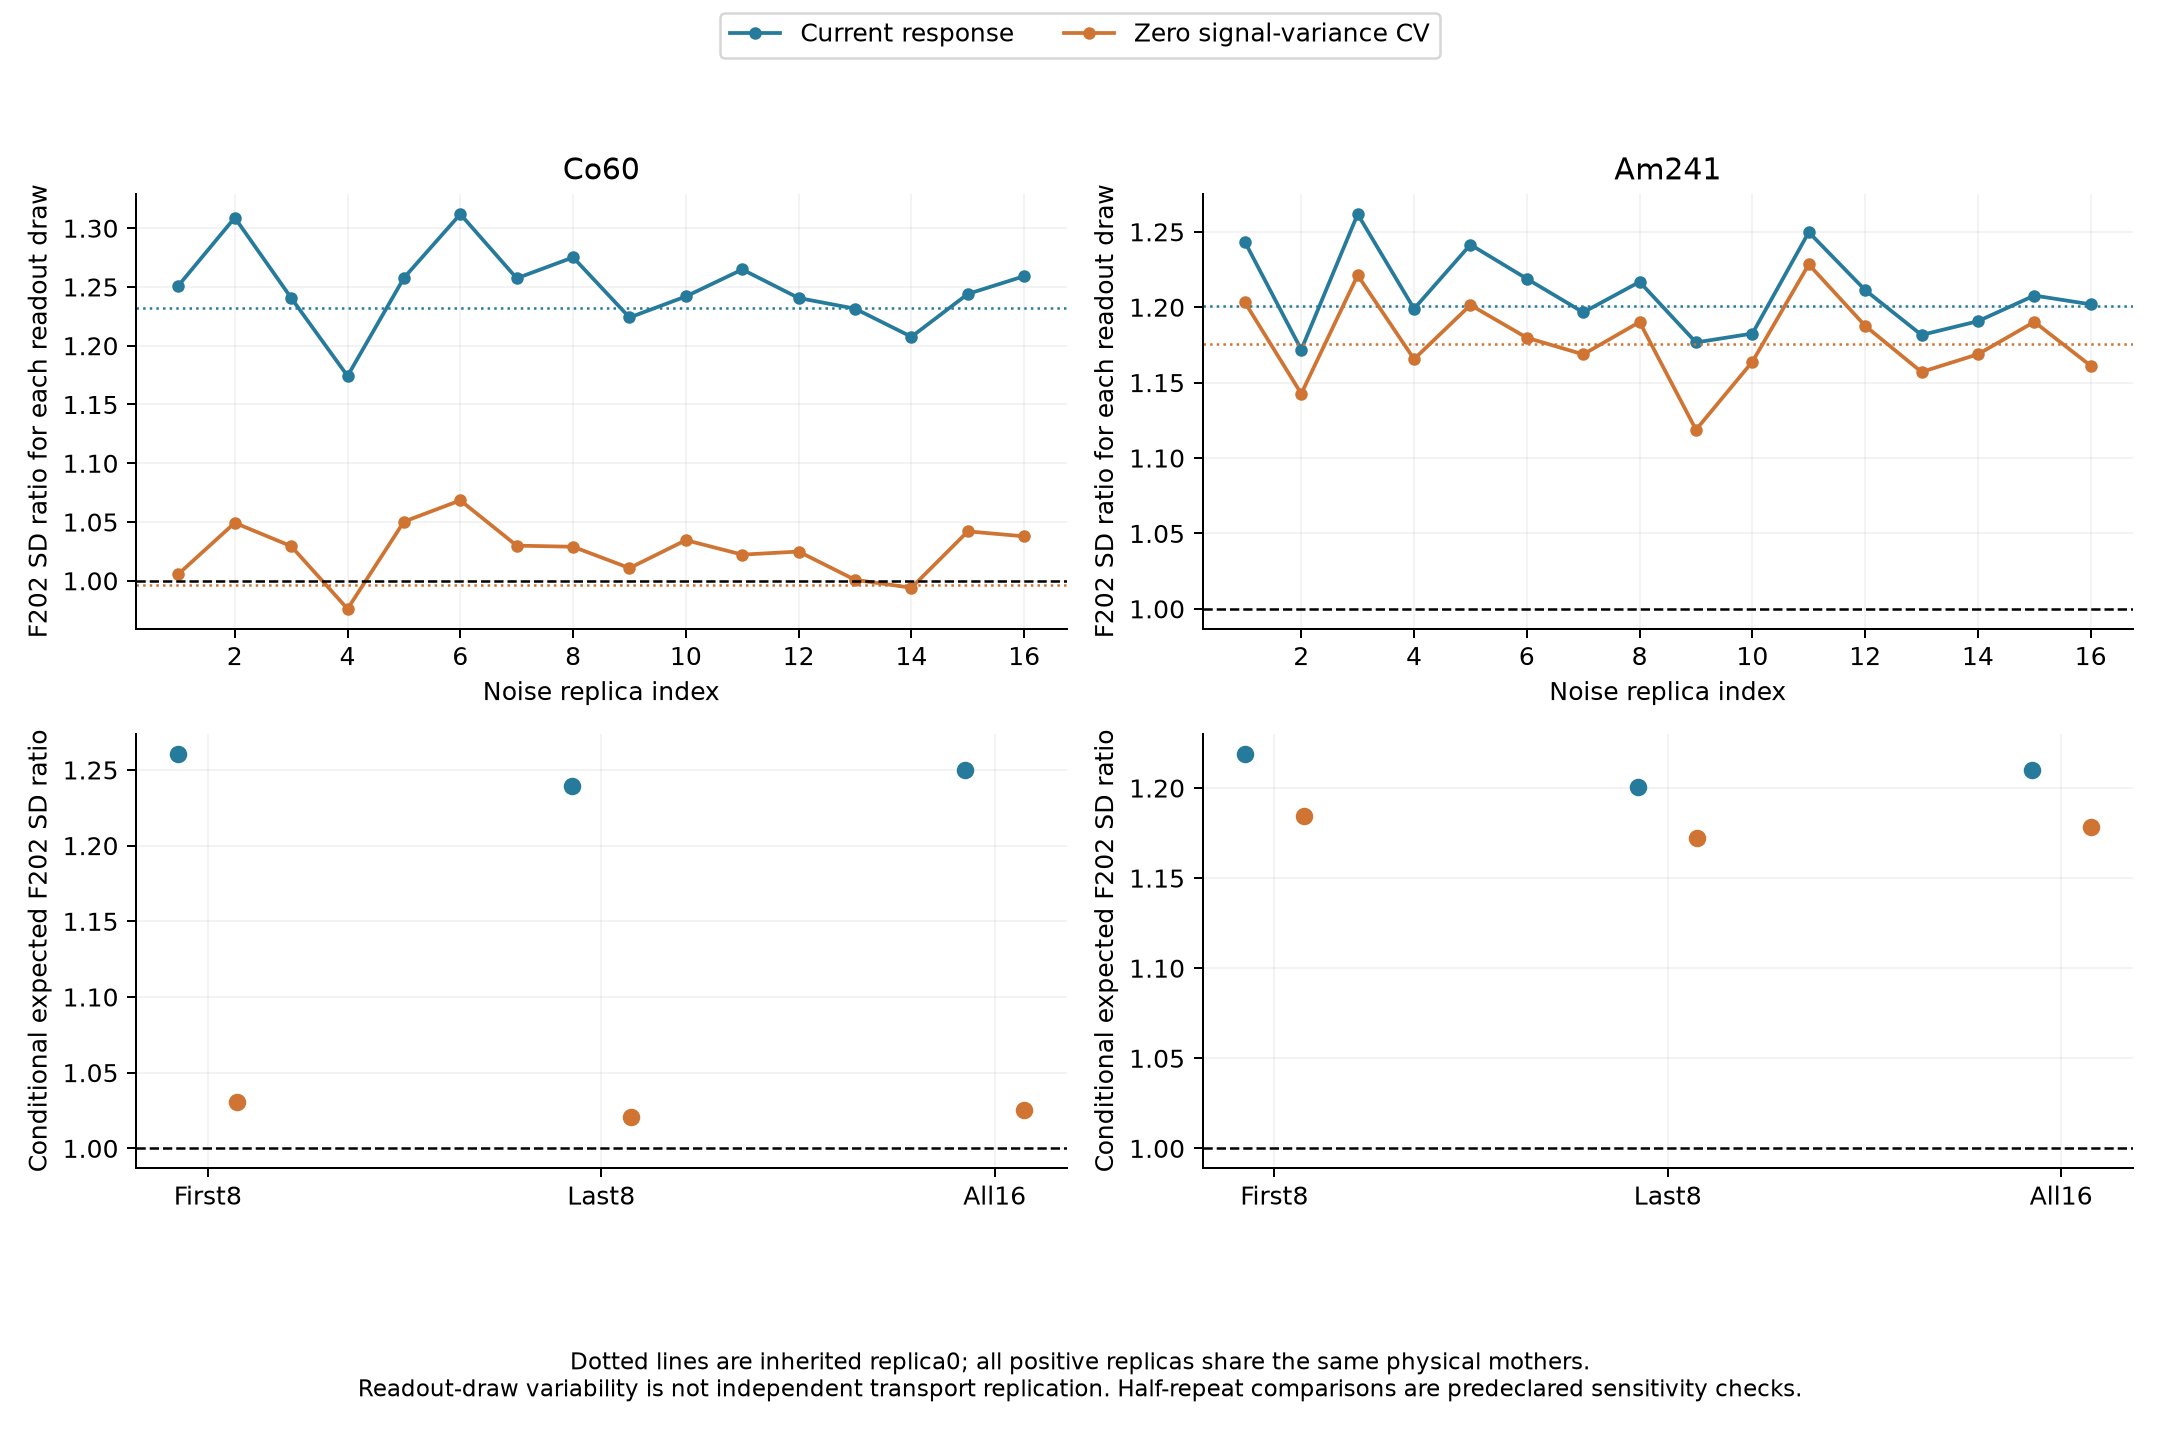

In [4]:
rows=[]
for source,g in repeated.items():
    for case,r in g['cases'].items():
        for name in ['F202_predicted_SD_ratio','F202_within_fraction','F202_between_fraction']:
            rows.append([source,case,name,fmt(r['point'][name]),ci(r['CI95'][name])])
display(Markdown(table(['源','重复流','指标','点值','条件95%范围'],rows)))
display(Image(filename=str(OUT/'figures/noise_repeat_decomposition.png')))
display(Image(filename=str(OUT/'figures/noise_repeat_convergence.png')))

## 4. 最小参数对照：仅将事件方差CV置零

当前信号相关残差为高斯FIR创新乘以随正信号幅度变化的标准差，再乘一个事件层的均值为1的对数正态方差因子。这里只将该因子的`event_variance_cv`置零，保留平均方差系数、FIR、电子学噪声、原始信号及传感器参数。原CV已为0的条件直接复用相同文件，避免把相同计算虚报为独立记录。

Co原CV约0.19866；Am条件为0或约0.09048。本对照不是重新拟合。用同一批母事件、同一噪声创新及配对区间比较平均波形、F均值/SD、QDC/时间/PCA的SD与中心50%/95%宽度和PID协方差，避免只缩窄F202却破坏其他指标。

保护条件事先冻结：比值指标用`abs(log(ratio))`误差，中心差用绝对值，平均ADC与协方差用非负误差。任何原指标的配对误差增加区间下界>0，均作为保守的描述性退化警报；同时要求两个源晚段F202误差减少。固定分母F只作机制诊断。多指标区间未作多重比较校正，不能解释为统一显著性检验或等效性证明。


|run|指标|当前|零CV|零CV−当前：误差变化范围|
|---|---|---|---|---|
|3|F50_SD_ratio|0.9765|0.6364|[0.3319, 0.4573] (512/512)|
|3|F102_SD_ratio|1.157|0.8201|[-0.07999, 0.1869] (512/512)|
|3|F202_SD_ratio|1.232|0.9965|[-0.2341, -0.1053] (512/512)|
|3|QDC_width50_ratio|1.066|1.076|[-0.0203, 0.01896] (512/512)|
|3|QDC_width95_ratio|1.072|1.077|[-0.0156, 0.01623] (512/512)|
|3|negative_mean_time_us_width50_ratio|0.9567|0.9558|[-0.01665, 0.01858] (512/512)|
|3|negative_mean_time_us_width95_ratio|1.006|1.021|[-0.01692, 0.02066] (512/512)|
|3|mean_ADC_relative_L2|0.02997|0.02996|[-5.256e-05, 1.867e-05] (512/512)|
|3|PID_covariance_relative_error|0.03766|0.03506|[-0.006644, 0.005541] (512/512)|
|12|F50_SD_ratio|0.9412|0.8921|[0.009845, 0.073] (512/512)|
|12|F102_SD_ratio|1.049|1.011|[-0.05228, 0.041] (512/512)|
|12|F202_SD_ratio|1.201|1.176|[-0.0347, -0.008308] (512/512)|
|12|QDC_width50_ratio|1.014|1.018|[-0.01575, 0.01907] (512/512)|
|12|QDC_width95_ratio|1.09|1.09|[-0.01844, 0.008695] (512/512)|
|12|negative_mean_time_us_width50_ratio|0.9414|0.9458|[-0.01143, 0.01258] (512/512)|
|12|negative_mean_time_us_width95_ratio|0.9798|0.9832|[-0.01393, 0.01102] (512/512)|
|12|mean_ADC_relative_L2|0.01597|0.01599|[-3.575e-05, 6.637e-05] (512/512)|
|12|PID_covariance_relative_error|0.05494|0.05575|[-0.004072, 0.00566] (512/512)|

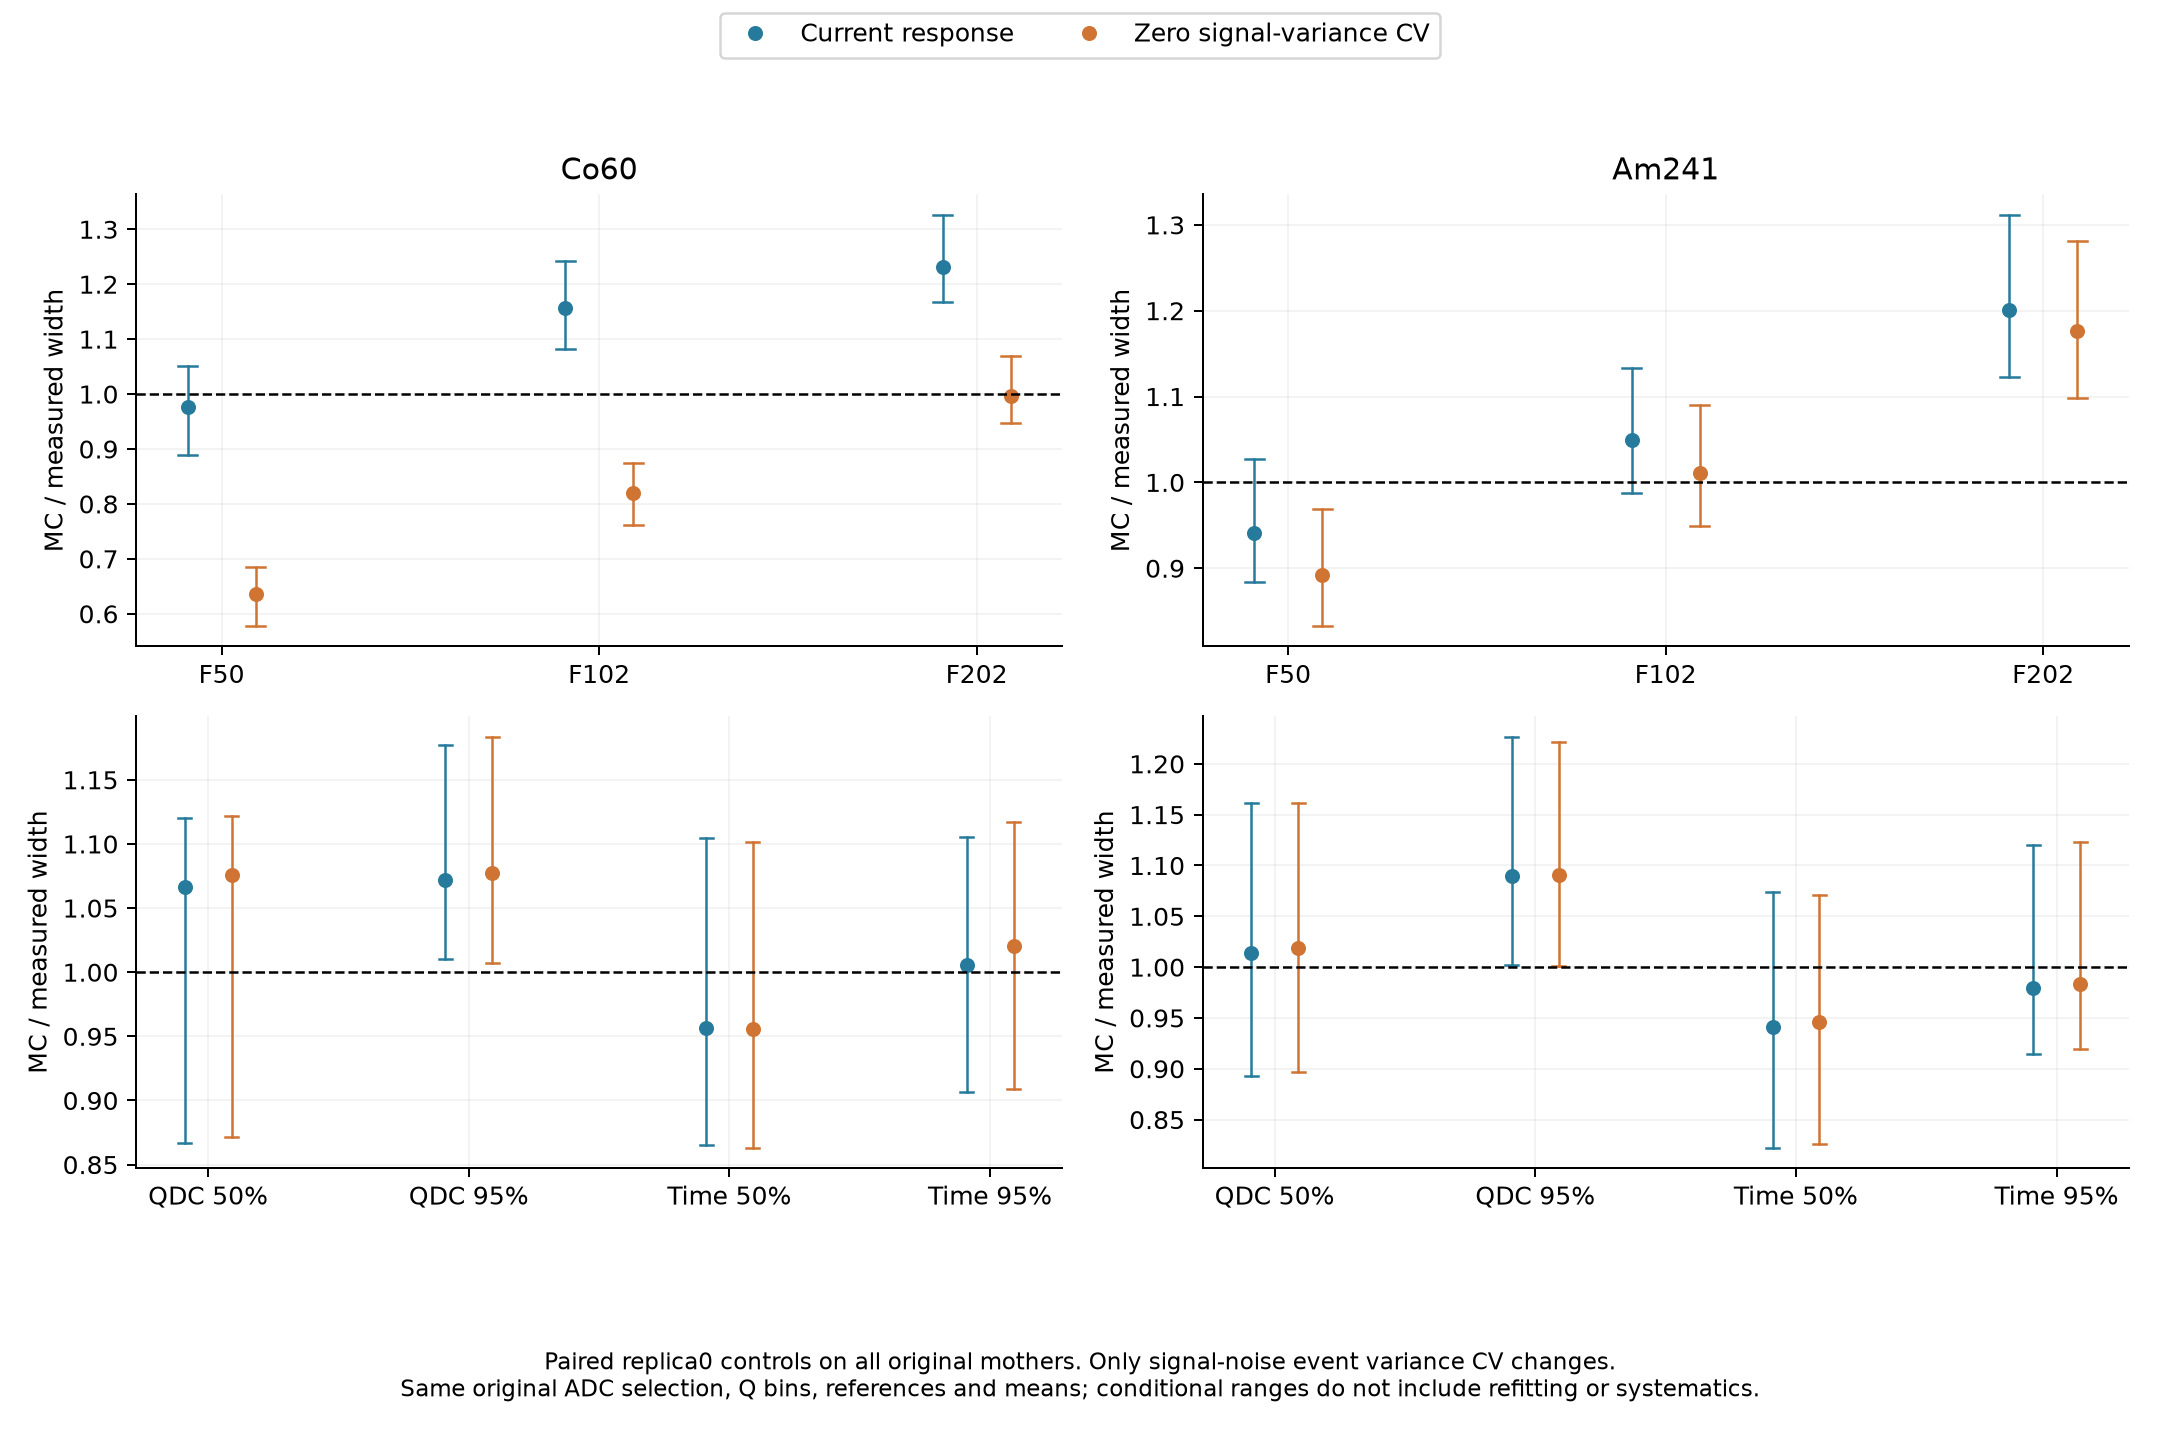

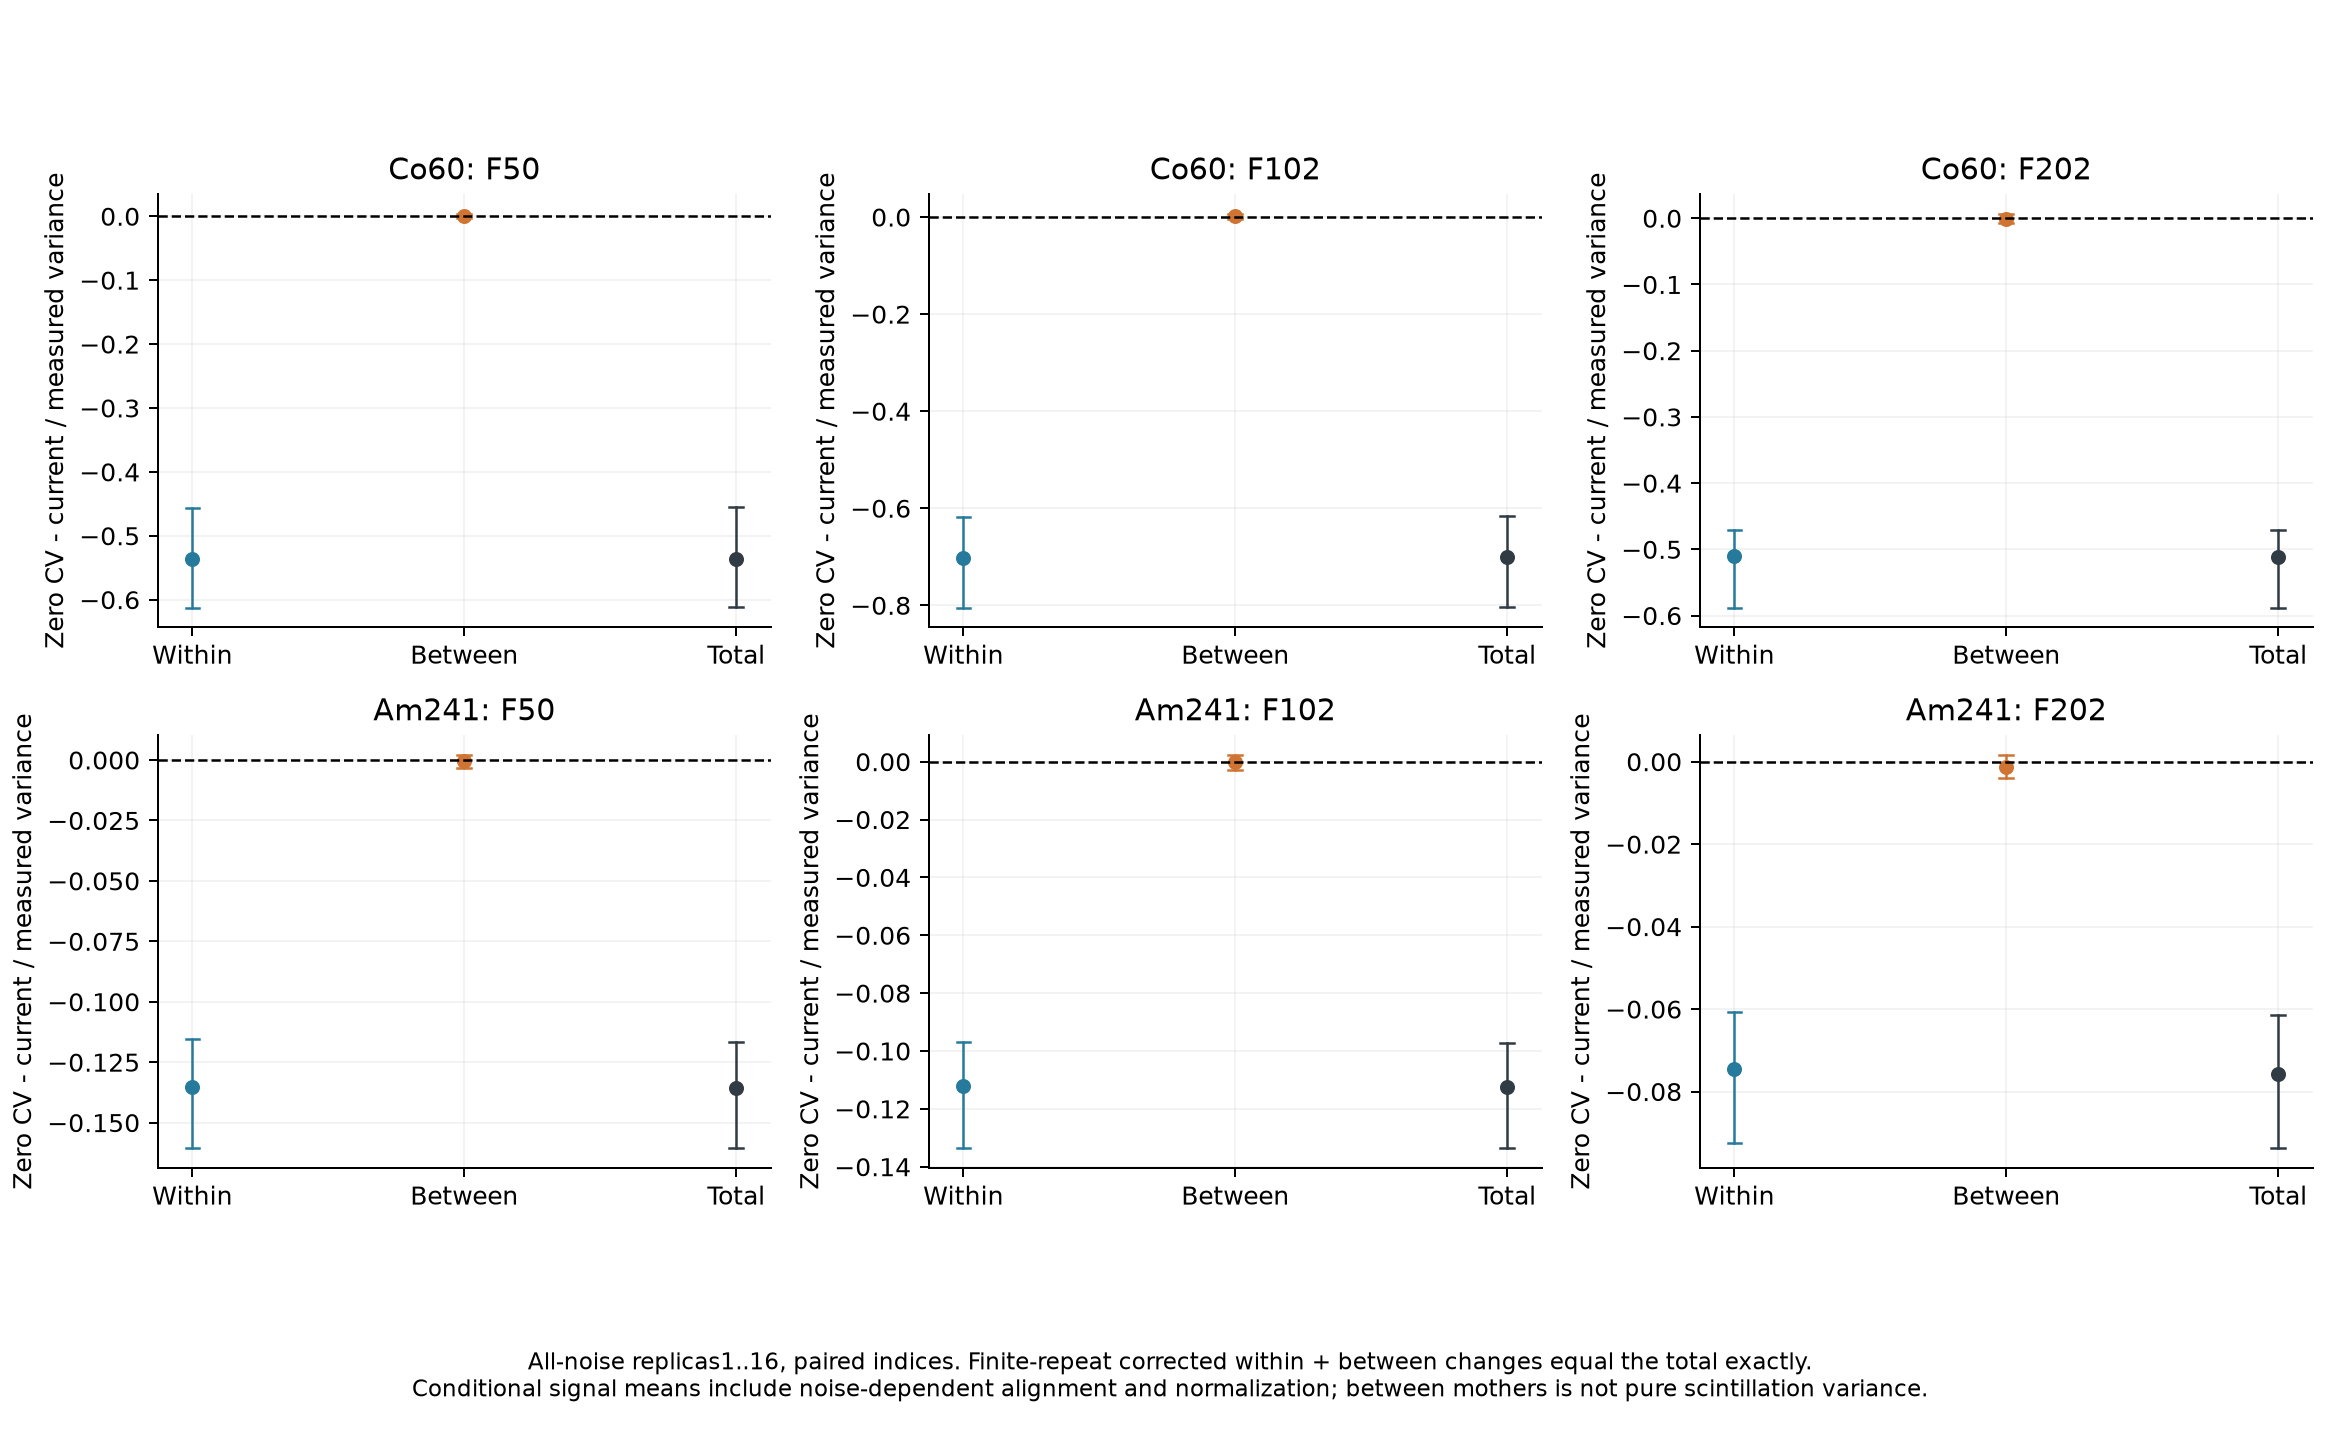

In [5]:
names=['F50_SD_ratio','F102_SD_ratio','F202_SD_ratio','QDC_width50_ratio','QDC_width95_ratio',
       'negative_mean_time_us_width50_ratio','negative_mean_time_us_width95_ratio','mean_ADC_relative_L2','PID_covariance_relative_error']
rows=[]
for run in [3,12]:
    g=points[f'run{run}_last20_B128']
    for name in names:
        rows.append([run,name,fmt(g['variants']['current']['point'][name]),fmt(g['variants']['zero_cv']['point'][name]),
                     ci(g['loss_change_zero_minus_current']['CI95'][name])])
display(Markdown(table(['run','指标','当前','零CV','零CV−当前：误差变化范围'],rows)))
display(Image(filename=str(OUT/'figures/noise_zero_cv_joint_checks.png')))
display(Image(filename=str(OUT/'figures/noise_cv_component_changes.png')))

## 5. 平均波形与全部采集条件

波形图采用原Q目标、原事件权重的基线扣除ADC均值，不逐事件缩放幅度，不通过修改滤波或积分门来对齐。每条重复都重新从ADC定位t10与计算特征；无噪声信号本身逐点不变，有限噪声及定位可改变最终均ADC图。

所有前/中/晚段和块64/128保留。原Q分箱依然来自继承ADC；重放的`qcalc`有保存，但不重新筛选或改箱。因此本轮不是“每次重放后重新触发、重新按当前电荷选择”的端到端验证，电荷条件影响仍需单独检查。


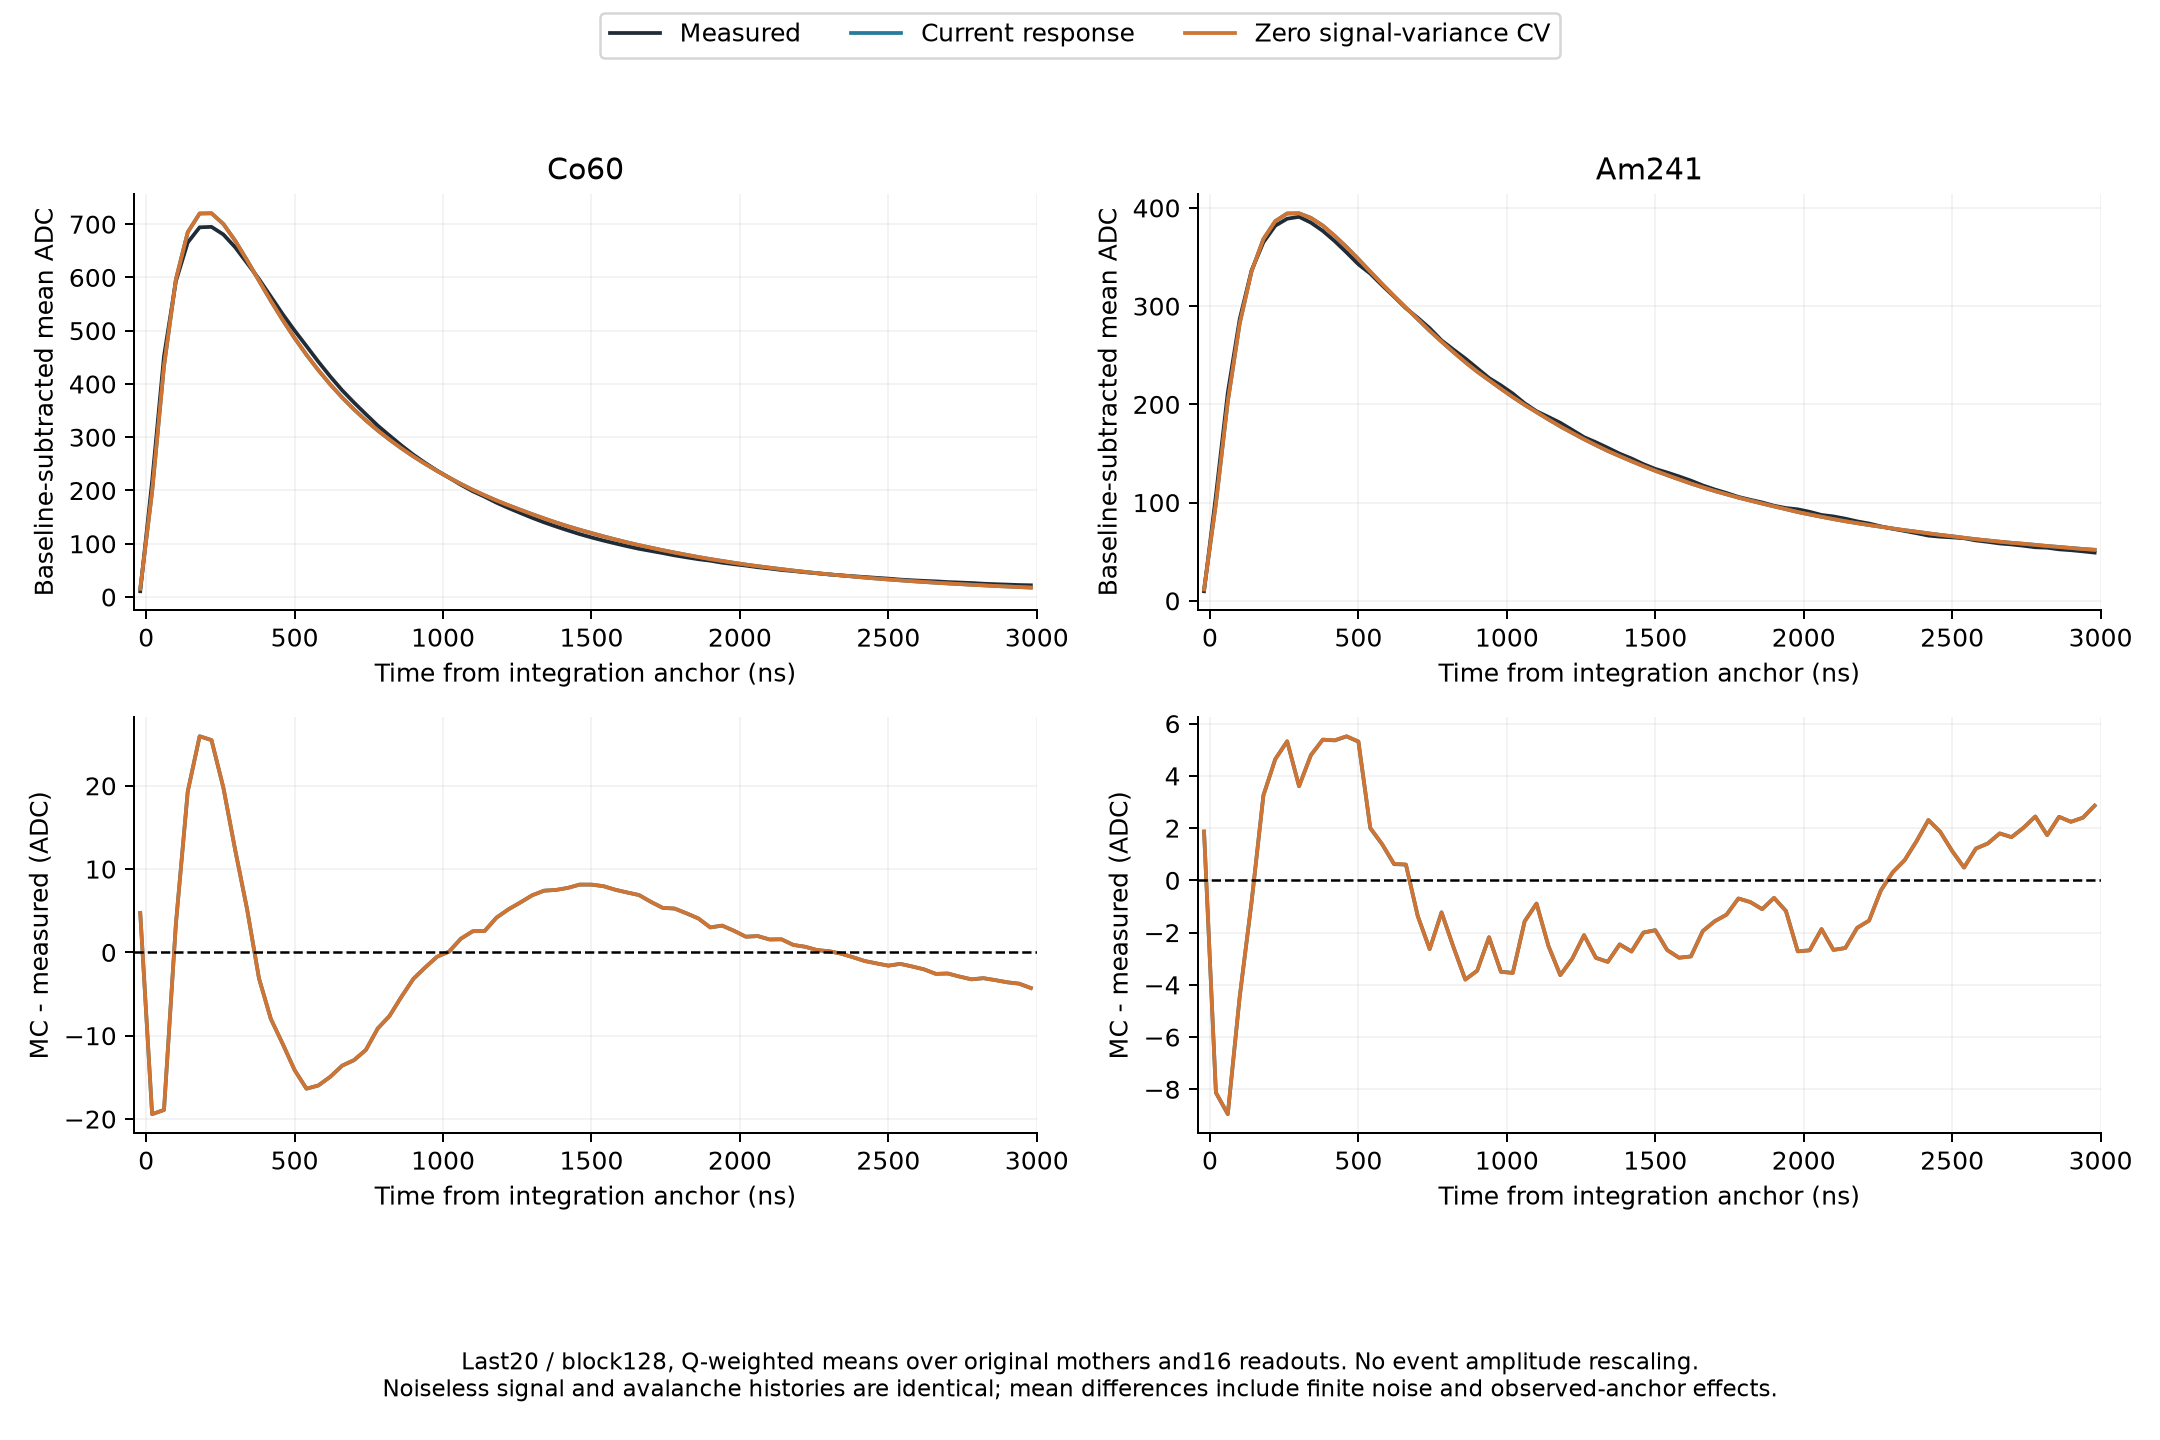

|条件|当前F202 SD比|零CV比|F202误差变化范围|明确退化项数|
|---|---|---|---|---|
|run3_first60_B64|1.114|0.9008|[-0.1176, 0.1077] (512/512)|1|
|run3_first60_B128|1.115|0.8994|[-0.1047, 0.0961] (512/512)|1|
|run3_middle20_B64|1.093|0.8842|[-0.1311, 0.1217] (512/512)|1|
|run3_middle20_B128|1.099|0.8871|[-0.147, 0.1023] (512/512)|1|
|run3_last20_B64|1.226|0.9926|[-0.2313, -0.07937] (512/512)|1|
|run3_last20_B128|1.232|0.9965|[-0.2341, -0.1053] (512/512)|1|
|run12_first60_B64|1.027|0.9884|[-0.04985, 0.04394] (512/512)|1|
|run12_first60_B128|0.988|0.988|[0, 0] (512/512)|0|
|run12_middle20_B64|1.107|1.073|[-0.04391, 0.02061] (512/512)|1|
|run12_middle20_B128|1.074|1.074|[0, 0] (512/512)|0|
|run12_last20_B64|1.181|1.181|[0, 0] (512/512)|0|
|run12_last20_B128|1.201|1.176|[-0.0347, -0.008308] (512/512)|1|

**下一步：**围绕明确恶化的尺度/指标构建有针对性的噪声波动模型，并核查当前ADC电荷条件对分布的影响。单一全事件方差乘子不足以由本轮结果自动升级；候选通过联合约束后再冻结新母事件验证。

边界：实验只有来源标签。Am包含α、γ与电子贡献；主带和MC真实来源信息不能用来宣称实验粒子纯度。

边界：母事件及原Q来自原ADC的质量/共同电荷选择，重复读出不重新选择。条件内机制诊断不等于完整触发、重新计算电荷选择或源人群效率的验证。

边界：信号-only或电子学-only固定另一噪声在零号实现，其方差不能作为两个可相加的独立物理成分。

边界：不同母事件间的项包含噪声条件均值、定位与归一化效应；有限重复校正可能为负，不能截零或当作独立闪烁方差。

边界：512次区间按原实验块和完整母事件抽样，所有重复随母事件一起抽取；不把重复当作独立Geant4统计。区间固定参数/参考，不含拟合和系统误差。

边界：保护条件中的多项区间只是保守的描述性警报，未作多重比较修正。所有实验及本MC池均已探索，不是盲验证。

In [6]:
display(Image(filename=str(OUT/'figures/noise_mean_waveforms.png')))
rows=[]
for context,g in points.items():
    r=g['variants'];loss=g['loss_change_zero_minus_current']
    rows.append([context,fmt(r['current']['point']['F202_SD_ratio']),fmt(r['zero_cv']['point']['F202_SD_ratio']),
                 ci(loss['CI95']['F202_SD_ratio']),sum(x['context']==context for x in decision['clear_loss_regressions'])])
display(Markdown(table(['条件','当前F202 SD比','零CV比','F202误差变化范围','明确退化项数'],rows)))
display(Markdown('**下一步：**'+decision['next_work_zh']))
for limit in decision['limitations_zh']:display(Markdown('边界：'+limit))

## 6. 可追溯记录

`selection_protocol.json`、`replay_protocol.json`、`analysis_protocol.json`分别冻结主带审计、原生重放、有限重复与联合指标；输入、源码和二进制有SHA256。`replay_execution.json`汇总24份执行收据，每份保存ROOT和特征数组哈希、零号一致性与不变信号核查。

`selection_table.csv`有144行，`zero_cv_point_table.csv`有24行，`zero_cv_loss_table.csv`有264行，`repeat_table.csv`有8行。完整逐Q协方差、512组母事件/实验块计数及配对分解位于各`*_evaluation/`目录，原生记录在`replay/`，紧凑特征在`arrays/`与`repeat_arrays/`。大ROOT/NPZ按项目惯例不进入Git，但本地保留并封存哈希。`verification.json`记录独立种子计算、直接卷积窗口、加权协方差及笔记核验；`record.json`封存输出和源码快照。

流程：`prepare_noise_selection.py` → `audit_noise_selection.py` → 构建独立C++目录/`test_noise_replay.py` → `prepare_noise_replay.py` → `run_noise_replay.py` → `analyze_noise_replay.py freeze/points/repeats` → `report_noise_replay.py` → 本笔记生成器 → `verify_noise_replay.py --archive`。本次分析方案在原生重放完成前已冻结。完整重跑应使用新的结果目录，不能覆盖已封存研究。

本轮没有联网、下载文献或修改共享文献库；没有修改默认模拟响应和正式PID。结论只覆盖上述对照，不能据此宣称PID带宽已经全面一致。
